---
### Exploratory Data Analysis

In [1]:
!pip install dash plotly pandas

In [2]:
import matplotlib.pyplot as plt
import plotly.express as px
from dash import Dash, Input, Output, dcc, html
from scipy.stats.mstats import trimmed_var
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [3]:
# Load the SCF dataset from compressed CSV
df = pd.read_csv("C:/Users/HomePC/Downloads/SCFP2019.csv.gz")  # read "data/SCFP2019.csv.gz"
print("df shape:", df.shape)
df.head()

df shape: (28885, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
0,1,11,6119.779308,2,75,6,12,4,2,0,...,5,3,6,3,2,10,6,6,3,3
1,1,12,4712.374912,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
2,1,13,5145.224455,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
3,1,14,5297.663412,2,75,6,12,4,2,0,...,5,2,6,2,1,10,4,4,2,2
4,1,15,4761.812371,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2


In [4]:
# Create a mask for credit-fearful households (TURNFEAR == 1)
mask = df["TURNFEAR"] == 1  
df_fear = df[mask]
print("df_fear shape:", df_fear.shape)
df_fear.head()

df_fear shape: (4623, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


In [5]:
# Verify dataset dimensions and subset
assert df.shape[1] == 351, (
    f"Expected 351 columns in df, got {df.shape[1]}"
)
assert df.shape[0] > 20000, (
    f"Expected more than 20000 rows in df, got {df.shape[0]}"
)
assert df_fear.shape[0] < df.shape[0], (
    "df_fear should be a subset smaller than df"
)
assert (df_fear["TURNFEAR"] == 1).all(), (
    "All rows in df_fear should have TURNFEAR == 1"
)
print("All checks passed!")

All checks passed!


In [6]:
# Get unique age group codes to understand the encoding
age_groups = df_fear["AGECL"].unique()  # unique values from df_fear["AGECL"]
print("Age Groups:", age_groups)

Age Groups: [3 5 1 2 4 6]


In [7]:
# Dictionary mapping age codes to labels (from Code Book)
agecl_dict = {
    1: "Under 35",
    2: "35-44",
    3: "45-54",
    4: "55-64",
    5: "65-74",
    6: "75 or Older",
}

# Replace numeric codes with descriptive labels
age_cl = df_fear["AGECL"].replace(agecl_dict)
age_cl.head()

5    45-54
6    45-54
7    45-54
8    45-54
9    45-54
Name: AGECL, dtype: object

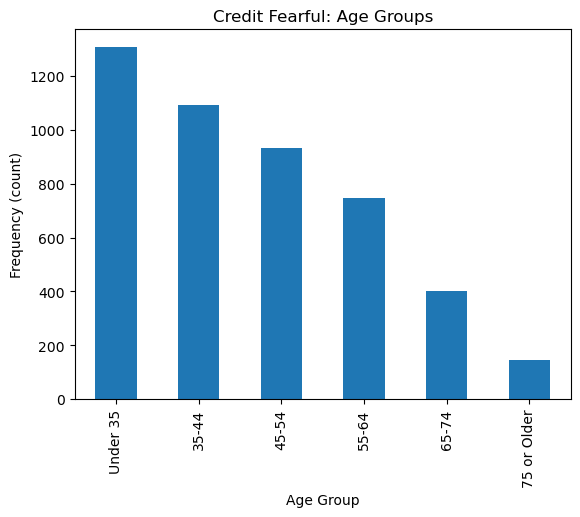

In [8]:
# Create bar chart of age group frequencies
age_cl_value_counts = age_cl.value_counts()  

# Plot bar chart
age_cl_value_counts.plot(
    kind="bar",
    xlabel="Age Group",
    ylabel="Frequency (count)",
    title="Credit Fearful: Age Groups"
);

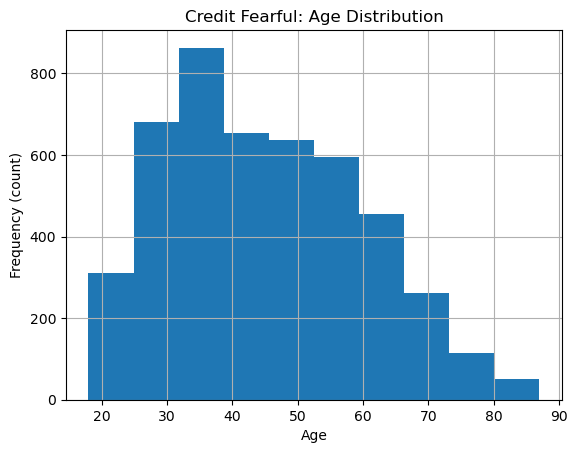

In [9]:
# Create histogram of continuous AGE variable for finer detail
df_fear["AGE"].hist(bins=10)  
plt.xlabel("Age")
plt.ylabel("Frequency (count)")
plt.title("Credit Fearful: Age Distribution");

In [10]:
# Verify age group processing
assert len(age_groups) == 6, (
    f"Expected 6 unique age groups, got {len(age_groups)}"
)
assert age_cl.dtype == object, (
    "age_cl should contain string labels after replacement"
)
assert age_cl_value_counts.sum() == len(df_fear), (
    f"Value counts should sum to {len(df_fear)}, got {age_cl_value_counts.sum()}"
)
print("All checks passed!")

All checks passed!


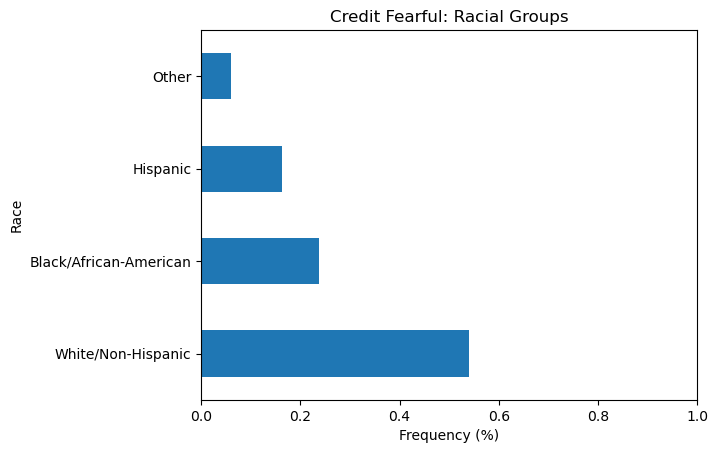

In [11]:
# Dictionary mapping race codes to labels (from Code Book)
race_dict = {
    1: "White/Non-Hispanic",
    2: "Black/African-American",
    3: "Hispanic",
    5: "Other",
}

# Create normalized bar chart for credit-fearful subset
race = df_fear["RACE"].replace(race_dict) 
race_value_counts = race.value_counts(normalize=True)  

# Plot horizontal bar chart
race_value_counts.plot(kind="barh")
plt.xlim((0, 1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("Credit Fearful: Racial Groups");

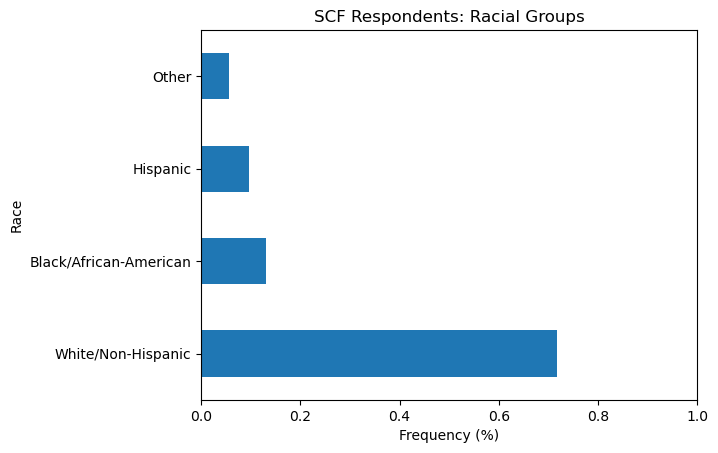

In [12]:
# Compare with full dataset to understand baseline proportions
race_full = df["RACE"].replace(race_dict)  # replace codes in df["RACE"] using race_dict
race_full_counts = race_full.value_counts(normalize=True)  # normalized value_counts

# Plot horizontal bar chart for full dataset
race_full_counts.plot(kind="barh")
plt.xlim((0, 1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("SCF Respondents: Racial Groups");

In [13]:
# Dictionary mapping income percentile codes to labels
inccat_dict = {
    1: "0-20",
    2: "21-39.9",
    3: "40-59.9",
    4: "60-79.9",
    5: "80-89.9",
    6: "90-100",
}

# Compute normalized frequencies by TURNFEAR group
df_inccat = (
    df["INCCAT"]
    .replace(inccat_dict)
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)  
    .rename("frequency") 
    .reset_index()  
)

df_inccat

,TURNFEAR,INCCAT,frequency
0,0,90-100,0.297296
1,0,60-79.9,0.174841
2,0,40-59.9,0.143146
3,0,0-20,0.140343
4,0,21-39.9,0.135933
5,0,80-89.9,0.108441
6,1,0-20,0.288125
7,1,21-39.9,0.256327
8,1,40-59.9,0.228856
9,1,60-79.9,0.132598


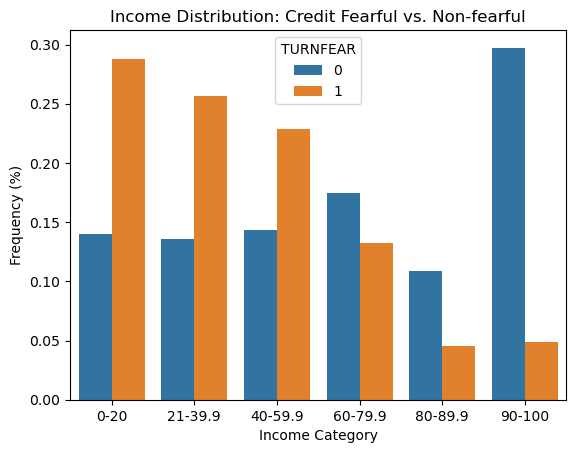

In [14]:
# Create side-by-side bar chart comparing income distributions
sns.barplot(
    x="INCCAT",  
    y="frequency",  
    hue="TURNFEAR",  
    data=df_inccat,
    order=list(inccat_dict.values()),
)
plt.xlabel("Income Category")
plt.ylabel("Frequency (%)")
plt.title("Income Distribution: Credit Fearful vs. Non-fearful");

In [15]:
# Compute correlation between ASSET and HOUSES for full dataset
asset_house_corr_full = df["ASSET"].corr(df["HOUSES"])  # correlation of df["ASSET"] with df["HOUSES"]
print("SCF: Asset-Houses Correlation:", round(asset_house_corr_full, 3))

SCF: Asset-Houses Correlation: 0.52


In [16]:
# Define columns for correlation matrix
cols = ["ASSET", "HOUSES", "INCOME", "DEBT", "EDUC"]

# Compute correlation matrix for full dataset
corr_full = df[cols].corr() # correlation matrix for df[cols]
corr_full.style.background_gradient(axis=None)

,ASSET,HOUSES,INCOME,DEBT,EDUC
ASSET,1.000000,0.519827,0.622429,0.261250,0.116673
HOUSES,0.519827,1.000000,0.247852,0.266661,0.169300
INCOME,0.622429,0.247852,1.000000,0.114646,0.069400
DEBT,0.261250,0.266661,0.114646,1.000000,0.054179
EDUC,0.116673,0.169300,0.069400,0.054179,1.000000


In [17]:
# Compute correlation matrix for credit-fearful subset
corr_fear = df_fear[cols].corr()  
corr_fear.style.background_gradient(axis=None)

,ASSET,HOUSES,INCOME,DEBT,EDUC
ASSET,1.000000,0.583288,0.722074,0.474658,0.113536
HOUSES,0.583288,1.000000,0.264099,0.962629,0.160348
INCOME,0.722074,0.264099,1.000000,0.172393,0.133170
DEBT,0.474658,0.962629,0.172393,1.000000,0.177386
EDUC,0.113536,0.160348,0.133170,0.177386,1.000000


In [18]:
# Compute education frequencies by TURNFEAR group
# Note: We keep numeric codes for EDUC (grade levels) for ordering
df_educ = (
    df["EDUC"]
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)
    .rename("frequency")
    .reset_index()
)
df_educ.head()

,TURNFEAR,EDUC,frequency
0,0,12,0.257481
1,0,8,0.192029
2,0,13,0.149823
3,0,9,0.129833
4,0,14,0.096117


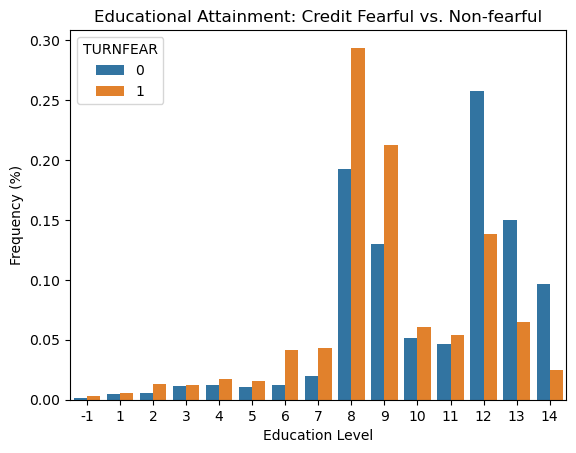

In [19]:
# Create side-by-side bar chart for education
sns.barplot(x="EDUC", y="frequency", hue="TURNFEAR", data=df_educ) 
plt.xlabel("Education Level")
plt.ylabel("Frequency (%)")
plt.title("Educational Attainment: Credit Fearful vs. Non-fearful");

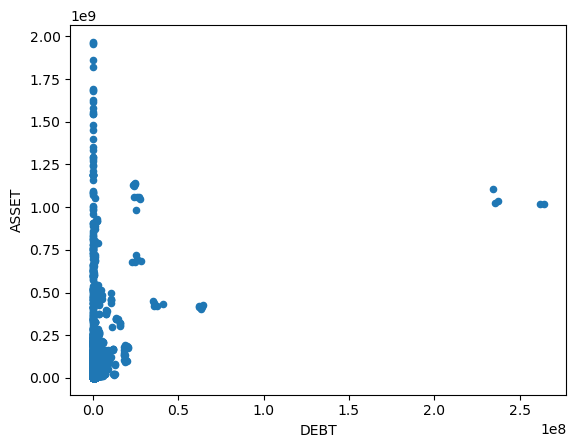

In [20]:
# Create scatter plot of DEBT vs ASSET for full dataset
df.plot.scatter(x="DEBT", y="ASSET"); # x="DEBT", y="ASSET"

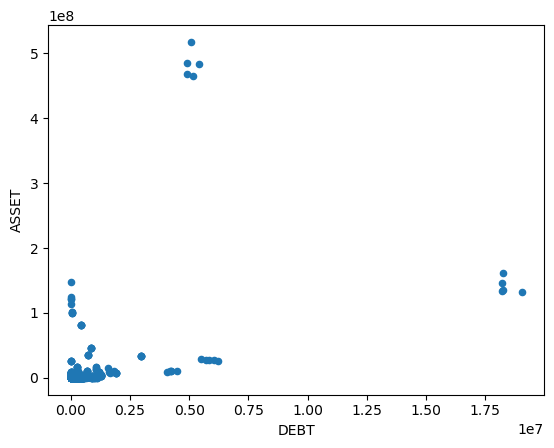

In [21]:
# Create scatter plot of DEBT vs ASSET for credit-fearful subset
df_fear.plot.scatter(x="DEBT", y="ASSET");  # x="DEBT", y="ASSET"

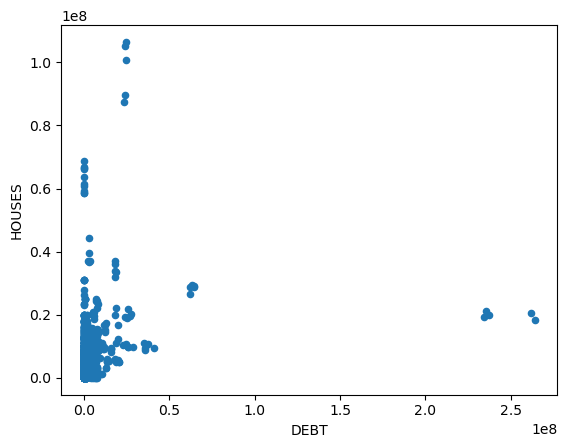

In [22]:
# Create scatter plot of DEBT vs HOUSES for full dataset
df.plot.scatter(x="DEBT", y="HOUSES");  # x="DEBT", y="HOUSES"

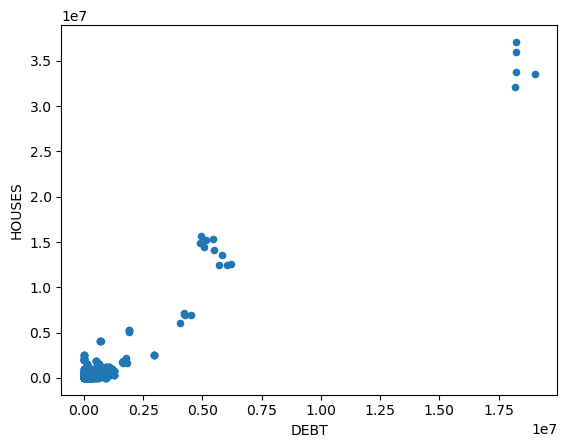

In [23]:
# Create scatter plot of DEBT vs HOUSES for credit-fearful subset
df_fear.plot.scatter(x="DEBT", y="HOUSES");  # x="DEBT", y="HOUSES"

---
### Clustering with two features

In [24]:
# Define a wrangle function that:
def wrangle(filepath):
    # Read the CSV file into a DataFrame
    df = pd.read_csv(filepath)

    # Filter for rows where TURNFEAR equals 1
    df = df[df["TURNFEAR"] == 1]

    # Return the filtered DataFrame
    return df

In [25]:
# Use wrangle to load the data into df
df = wrangle("C:/Users/HomePC/Downloads/SCFP2019.csv.gz")
print("DataFrame shape:", df.shape)
df.head()

DataFrame shape: (4623, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


In [26]:
# Create feature matrix X with columns "DEBT" and "HOUSES"
X = df[["DEBT", "HOUSES"]]
print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (4623, 2)


,DEBT,HOUSES
5,12200.0,0.0
6,12600.0,0.0
7,15300.0,0.0
8,14100.0,0.0
9,15400.0,0.0


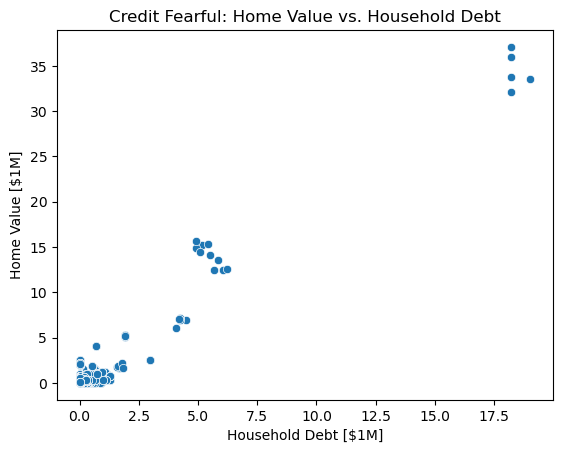

In [27]:
# Create a scatter plot of HOUSES vs DEBT (scaled to millions)
sns.scatterplot(x=df["DEBT"] / 1e6, y=df["HOUSES"] / 1e6)
plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Credit Fearful: Home Value vs. Household Debt");

In [28]:
# Build and fit a KMeans model with n_clusters=3 and random_state=42
model = KMeans(n_clusters=3, random_state=42)
model.fit(X)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [29]:
# Extract cluster labels from the fitted model
labels = model.labels_
print("First 10 labels:", labels[:10])

First 10 labels: [0 0 0 0 0 0 0 0 0 0]


In [30]:
# Extract centroids from the fitted model
centroids = model.cluster_centers_
print("Centroids shape:", centroids.shape)
print("Centroids:\n", centroids)

Centroids shape: (3, 2)
Centroids:
 [[   91017.57766674   116150.29328699]
 [18384100.         34484000.        ]
 [ 5065800.         11666666.66666667]]


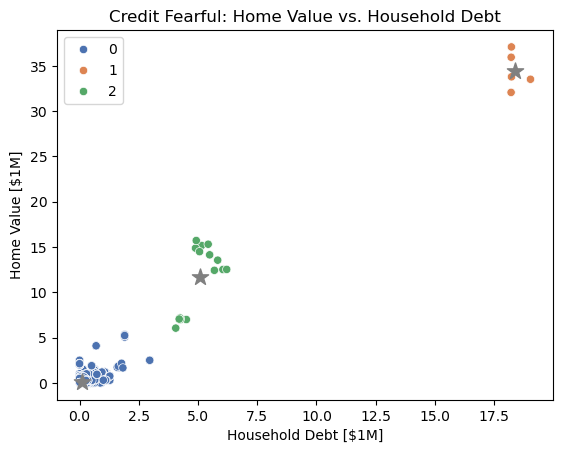

In [31]:
# Create scatter plot with points colored by cluster (use hue=labels)
# Use sns.scatterplot with x, y scaled to millions, hue=labels
sns.scatterplot(
    x=df["DEBT"] / 1e6, y=df["HOUSES"] / 1e6, hue=labels, palette="deep"
)
# Add centroids as gray stars (marker="*", s=150)
plt.scatter(
    centroids[:, 0] / 1e6, centroids[:, 1] / 1e6,
    color="gray", marker="*", s=150
)
plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Credit Fearful: Home Value vs. Household Debt");

In [32]:
# Extract inertia from the model and calculate silhouette score
inertia = model.inertia_
ss = silhouette_score(X, model.labels_)
print("Inertia (3 clusters):", inertia)
print("Silhouette Score (3 clusters):", ss)

Inertia (3 clusters): 939554010797046.9
Silhouette Score (3 clusters): 0.9768842462944348


In [33]:
# Loop over n_clusters from 2 to 12 (inclusive)
n_clusters = range(2, 13)
inertia_errors = []
silhouette_scores = []

for k in n_clusters:
    temp_model = KMeans(n_clusters=k, random_state=42)
    temp_model.fit(X)
    inertia_errors.append(temp_model.inertia_)
    silhouette_scores.append(silhouette_score(X, temp_model.labels_))

print("Inertia values:", inertia_errors)
print("Silhouette scores:", silhouette_scores)

Inertia values: [3018038313336920.0, 939554010797046.9, 546098841715654.56, 312953826439184.1, 259345573699045.4, 190276466219404.1, 182823496442976.0, 137854230409643.17, 101281028664353.95, 94456305764353.97, 82784036332859.47]
Silhouette scores: [0.9855099957519555, 0.9768842462944348, 0.9490311483406091, 0.8145735206135484, 0.8098677144717595, 0.7283895532760676, 0.7292682050725934, 0.7303424143073027, 0.733219368089596, 0.7338888149535772, 0.7323568183281238]


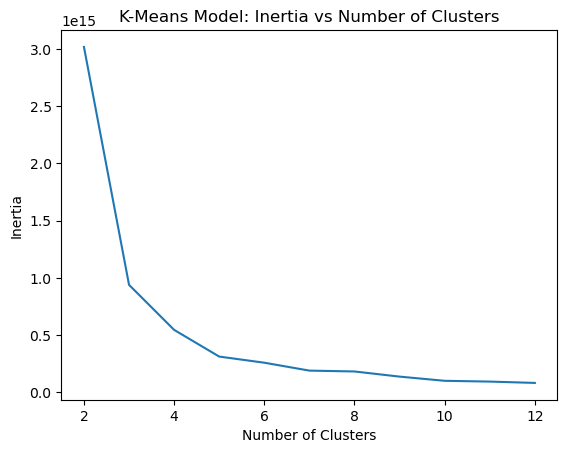

In [34]:
# Create a line plot of inertia_errors vs n_clusters
plt.plot(n_clusters, inertia_errors)
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("K-Means Model: Inertia vs Number of Clusters");

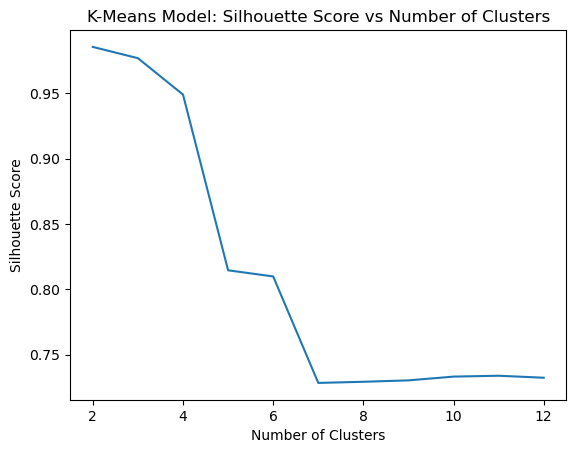

In [35]:
# Create a line plot of silhouette_scores vs n_clusters
plt.plot(n_clusters, silhouette_scores)
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Model: Silhouette Score vs Number of Clusters");

In [36]:
# Build and fit final_model with n_clusters=4 and random_state=42
final_model = KMeans(n_clusters=4, random_state=42)
final_model.fit(X)


,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


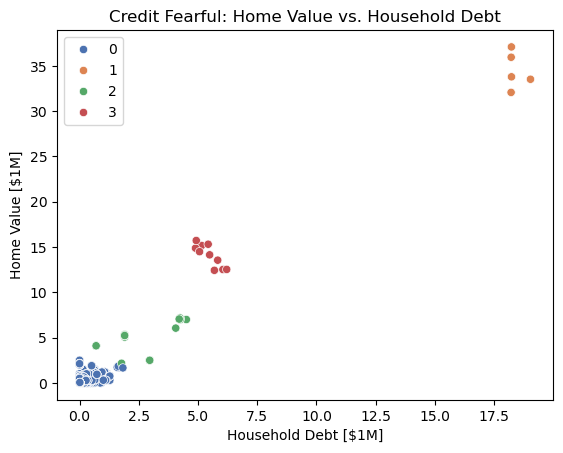

In [37]:
# Create scatter plot with final_model labels
# Color points by cluster using hue=final_model.labels_
sns.scatterplot(
    x=df["DEBT"] / 1e6, y=df["HOUSES"] / 1e6,
    hue=final_model.labels_, palette="deep"
)
plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Credit Fearful: Home Value vs. Household Debt");

In [38]:
# Create DataFrame xgb with mean DEBT and HOUSES per cluster

xgb = X.groupby(final_model.labels_).mean()
xgb

,DEBT,HOUSES
0,8.488629e+04,1.031872e+05
1,1.838410e+07,3.448400e+07
2,2.420929e+06,4.551429e+06
3,5.472800e+06,1.407400e+07


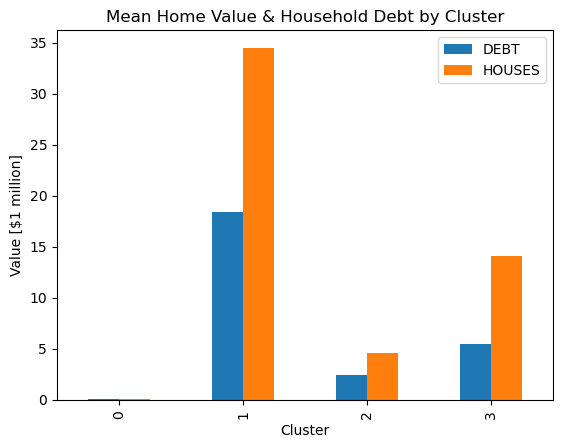

In [39]:
# Create side-by-side bar chart of xgb (divided by 1e6)
(xgb / 1e6).plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Value [$1 million]")
plt.title("Mean Home Value & Household Debt by Cluster");

---
### Clustering with multiplevfeatures

In [40]:
def wrangle(filepath):
    # Load CSV file
    df = pd.read_csv(filepath)
    # Create mask for credit-constrained households with NW < $2M
    mask = (df["TURNFEAR"] == 1) & (df["NETWORTH"] < 2e6)
    # Apply mask
    df = df[mask]
    return df

In [41]:
df = wrangle("C:/Users/HomePC/Downloads/SCFP2019.csv.gz")
print("DataFrame shape:", df.shape)
df.head()

DataFrame shape: (4418, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


In [42]:
# Calculate variance and get top 10
top_ten_var = df.var().sort_values().tail(10)
top_ten_var

PLOAN1      1.140894e+10
ACTBUS      1.251892e+10
BUS         1.256643e+10
KGTOTAL     1.346475e+10
DEBT        1.848252e+10
NHNFIN      2.254163e+10
HOUSES      2.388459e+10
NETWORTH    4.847029e+10
NFIN        5.713939e+10
ASSET       8.303967e+10
dtype: float64

In [43]:
# Create horizontal bar chart
fig = px.bar(
    x=top_ten_var,
    y=top_ten_var.index,
    orientation="h",
    title="SCF: High Variance Features"
)
fig.update_layout(xaxis_title="Variance", yaxis_title="Feature")
fig.show()

In [44]:
# Create boxplot to examine distribution
fig = px.box(
    data_frame=df,
    x="NHNFIN",
    title="Distribution of Non-home, Non-Financial Assets"
)
fig.update_layout(xaxis_title="Value [$]")
fig.show()

In [45]:
# Calculate trimmed variance (trim 10% from each tail) for all features
top_ten_trim_var = (
    df.apply(trimmed_var, limits=(0.1, 0.1)).sort_values().tail(10)
)
top_ten_trim_var

WAGEINC     5.550737e+08
HOMEEQ      7.338377e+08
NH_MORT     1.333125e+09
MRTHEL      1.380468e+09
PLOAN1      1.441968e+09
DEBT        3.089865e+09
NETWORTH    3.099929e+09
HOUSES      4.978660e+09
NFIN        8.456442e+09
ASSET       1.175370e+10
dtype: float64

In [46]:
# Create horizontal bar chart of trimmed variance
fig = px.bar(
    x=top_ten_trim_var,
    y=top_ten_trim_var.index,
    orientation="h",
    title="SCF: High Variance Features"
)
fig.update_layout(xaxis_title="Trimmed Variance", yaxis_title="Feature")
fig.show()


In [47]:
# Extract the column names of the top 5 features by trimmed variance
# Convert to a list and assign to high_var_cols
high_var_cols = top_ten_trim_var.tail(5).index.to_list()
high_var_cols

['DEBT', 'NETWORTH', 'HOUSES', 'NFIN', 'ASSET']

In [48]:
# Create feature matrix with selected columns
X = df[high_var_cols]
print("X shape:", X.shape)
X.head()

X shape: (4418, 5)


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
5,12200.0,-6710.0,0.0,3900.0,5490.0
6,12600.0,-4710.0,0.0,6300.0,7890.0
7,15300.0,-8115.0,0.0,5600.0,7185.0
8,14100.0,-2510.0,0.0,10000.0,11590.0
9,15400.0,-5715.0,0.0,8100.0,9685.0


In [49]:
# Create X_summary with mean and std for all features in X
X_summary = X.agg(["mean", "std"]).astype(int)
X_summary

,DEBT,NETWORTH,HOUSES,NFIN,ASSET
mean,72701,76387,74530,117330,149089
std,135950,220159,154546,239038,288166


In [50]:
# Instantiate a StandardScaler
ss = StandardScaler()
# Fit and transform X, storing result in X_scaled_data
X_scaled_data = ss.fit_transform(X)
# Create DataFrame X_scaled with same column names as X
X_scaled = pd.DataFrame(X_scaled_data, columns=X.columns)
# Print shape and display first few rows
print("X_scaled shape:", X_scaled)
X_scaled.head()

X_scaled shape:           DEBT  NETWORTH    HOUSES      NFIN     ASSET
0    -0.445075 -0.377486 -0.482310 -0.474583 -0.498377
1    -0.442132 -0.368401 -0.482310 -0.464541 -0.490047
2    -0.422270 -0.383868 -0.482310 -0.467470 -0.492494
3    -0.431097 -0.358407 -0.482310 -0.449061 -0.477206
4    -0.421534 -0.372966 -0.482310 -0.457010 -0.483818
...        ...       ...       ...       ...       ...
4413 -0.458316  1.139362 -0.126389  0.921585  0.654252
4414 -0.458316  1.137999 -0.126389  0.920330  0.653211
4415 -0.458316  1.128914 -0.126389  0.911962  0.646270
4416 -0.458316  1.142088 -0.126389  0.924095  0.656335
4417 -0.458316  1.159804 -0.126389  0.940413  0.669870

[4418 rows x 5 columns]


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
0,-0.445075,-0.377486,-0.48231,-0.474583,-0.498377
1,-0.442132,-0.368401,-0.48231,-0.464541,-0.490047
2,-0.422270,-0.383868,-0.48231,-0.467470,-0.492494
3,-0.431097,-0.358407,-0.48231,-0.449061,-0.477206
4,-0.421534,-0.372966,-0.48231,-0.457010,-0.483818


In [51]:
# Create X_scaled_summary with mean and std for X_scaled
# Round to verify mean ≈ 0 and std ≈ 1
X_scaled_summary = X_scaled.agg(["mean", "std"]).round(2)
X_scaled_summary

,DEBT,NETWORTH,HOUSES,NFIN,ASSET
mean,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


In [52]:
n_clusters = range(2, 13)
inertia_errors = []
silhouette_scores = []

# Train models and collect metrics
for k in n_clusters:
    model = make_pipeline(
        StandardScaler(),
        KMeans(n_clusters=k, random_state=42)
    )
    model.fit(X)
    inertia_errors.append(model[-1].inertia_)
    silhouette_scores.append(silhouette_score(X, model[-1].labels_))

print("Inertia (first 3):", inertia_errors[:3])
print("Silhouette scores (first 3):", silhouette_scores[:3])

Inertia (first 3): [11028.058082607182, 7190.703769068726, 6233.106346879304]
Silhouette scores (first 3): [0.7464502937083215, 0.7042841259119152, 0.7046977054481021]


In [53]:
# Create a line plot of inertia_errors vs n_clusters
fig = px.line(
    x=n_clusters,
    y=inertia_errors,
    title="K-Means Model: Inertia vs Number of Clusters"
)
# Set x-axis to "Number of Clusters", y-axis to "Inertia"
fig.update_layout(xaxis_title="Number of Clusters", yaxis_title="Inertia")
fig.show()

In [54]:
# Create a line plot of silhouette_scores vs n_clusters
fig = px.line(
    x=n_clusters,
    y=silhouette_scores,
    title="K-Means Model: Silhouette Score vs Number of Clusters"
)
# Set x-axis to "Number of Clusters", y-axis to "Silhouette Score"
fig.update_layout(
    xaxis_title="Number of Clusters",
    yaxis_title="Silhouette Score"
)
fig.show()

In [55]:
# Create final_model pipeline with StandardScaler and KMeans
final_model = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=4, random_state=42)
)
# Fit the model on X
final_model.fit(X)

,steps,"[('standardscaler', ...), ('kmeans', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300


In [56]:
# Extract labels from final_model using named_steps["kmeans"].labels_
labels = final_model.named_steps["kmeans"].labels_
# Print the first 5 labels
print("First 5 labels:", labels[:5])

First 5 labels: [1 1 1 1 1]


In [57]:
# Group X by labels and calculate mean for each cluster
# Assign result to xgb (cluster profile DataFrame)
xgb = X.groupby(labels).mean()
xgb

,DEBT,NETWORTH,HOUSES,NFIN,ASSET
0,205111.440049,2.314333e+05,261927.688504,3.512653e+05,4.365447e+05
1,28650.810927,1.176536e+04,14647.482838,2.825256e+04,4.041617e+04
2,669360.967742,5.819507e+05,788306.451613,1.118355e+06,1.251312e+06
3,266576.274510,1.432137e+06,339117.647059,1.295769e+06,1.698713e+06


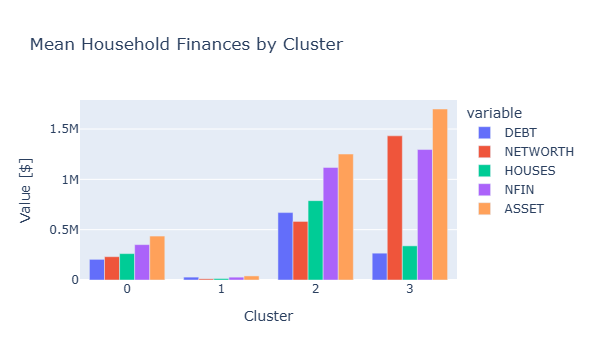

In [58]:
# Create grouped bar chart of cluster profiles
fig = px.bar(
    xgb,
    barmode="group",
    title="Mean Household Finances by Cluster"
)
# Set x-axis to "Cluster", y-axis to "Value [$]"
fig.update_layout(xaxis_title="Cluster", yaxis_title="Value [$]")
fig.show()

In [59]:
# Instantiate PCA with n_components=2 and random_state=42
pca = PCA(n_components=2, random_state=42)
# Fit and transform X, storing result in X_t
X_t = pca.fit_transform(X)
# Create DataFrame X_pca with columns "PC1" and "PC2"
X_pca = pd.DataFrame(X_t, columns=["PC1", "PC2"])
# Print shape and display first few rows
print("X_pca shape:", X_pca)
X_pca.head()

X_pca shape:                 PC1            PC2
0    -221525.424530   22052.273003
1    -217775.100722   22851.358068
2    -219519.642175   19023.646333
3    -212195.720367   22957.107039
4    -215540.507551   20259.749306
...             ...            ...
4413  326988.276480  183995.594411
4414  326508.031163  183831.963089
4415  323306.395719  182741.087608
4416  327948.767113  184322.857055
4417  334191.956229  186450.064242

[4418 rows x 2 columns]


,PC1,PC2
0,-221525.424530,22052.273003
1,-217775.100722,22851.358068
2,-219519.642175,19023.646333
3,-212195.720367,22957.107039
4,-215540.507551,20259.749306


In [60]:
# Create a scatter plot of X_pca with PC1 on x-axis, PC2 on y-axis
# Color points by cluster labels (convert to string for discrete colors)
fig = px.scatter(
    data_frame=X_pca,
    x="PC1",
    y="PC2",
    color=labels.astype(str),
    title="PCA Representation of Clusters"
)
fig.update_layout(xaxis_title="PC1", yaxis_title="PC2")
fig.show()

---
### Cluster Exploration using an interactive dashboard

In [61]:
def wrangle(filepath):
    """Read SCF data file into DataFrame.

    Returns only credit-fearful households whose net worth is less than
    $2 million.

    Parameters
    ----------
    filepath : str
        Location of CSV file.

    Returns
    -------
    pd.DataFrame
    """
    df = pd.read_csv(filepath)
    mask = (df["TURNFEAR"] == 1) & (df["NETWORTH"] < 2e6)
    df = df[mask]
    return df

In [62]:
df = wrangle("C:/Users/HomePC/Downloads/SCFP2019.csv.gz")
print(df.shape)
df.head()

(4418, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


In [63]:
# Instantiate the Dash application
app = Dash(__name__)

In [64]:
# Define the application layout
app.layout = html.Div(
    [
        # Headers
        html.H1("Survey of Consumer Finance"),
        html.H2("High Variance Features"),
        # Bar chart
        dcc.Graph(id="bar-chart"),
        # Radio buttons for trimmed variance
        dcc.RadioItems(
            options=[
                {"label": "trimmed", "value": True},
                {"label": "not trimmed", "value": False},
            ],
            value=5,
            id="trim-button",
        ),
        # K-means section headers
        html.H2("K-means Clustering"),
        html.H3("Number of Clusters(k)"),
        # Slider for k
        dcc.Slider(min=2, max=12, step=1, value=5, id="k-slider"),
        # Metrics display
        html.Div(id="metrics"),
        # PCA scatter plot
        dcc.Graph(id="pca-scatter"),
    ]
)

In [65]:
def get_high_var_features(trimmed=True, return_feat_names=False):
    """Return the five highest-variance features of df.

    Parameters
    ----------
    trimmed : bool, default=True
        If True, calculates trimmed variance, removing bottom and top 10%
        of observations.
    return_feat_names : bool, default=False
        If True, returns feature names as a list. If False, returns a Series
        where index is feature names and values are variances.

    Returns
    -------
    pd.Series or list
    """
    if trimmed:
        top_five = (
            df.apply(trimmed_var, limits=(0.1, 0.1)).sort_values().tail(5)
        )
    else:
        top_five = df.var().sort_values().tail(5)

    if return_feat_names:
        top_five = top_five.index.tolist()

    return top_five

In [66]:
@app.callback(Output("bar-chart", "figure"), Input("trim-button", "value"))
def serve_bar_chart(trimmed=True):
    """Return a horizontal bar chart of the five highest-variance features.

    Parameters
    ----------
    trimmed : bool, default=True
        If True, calculates trimmed variance.

    Returns
    -------
    plotly.graph_objects.Figure
    """
    top_five = get_high_var_features(trimmed, return_feat_names=False)
    fig = px.bar(x=top_five, y=top_five.index, orientation="h")
    fig.update_layout(xaxis_title="Variance", yaxis_title="Feature")
    return fig

In [67]:
def get_model_metrics(trimmed=True, k=2, return_metrics=False):
    """Build a KMeans model based on the five highest-variance features.

    Parameters
    ----------
    trimmed : bool, default=True
        If True, uses trimmed variance for feature selection.
    k : int, default=2
        Number of clusters.
    return_metrics : bool, default=False
        If False, returns the fitted KMeans pipeline. If True, returns a dict
        with 'inertia' and 'silhouette' keys.

    Returns
    -------
    sklearn.pipeline.Pipeline or dict
    """
    features = get_high_var_features(trimmed=trimmed, return_feat_names=True)
    X = df[features]
    model = make_pipeline(
        StandardScaler(),
        KMeans(n_clusters=k, random_state=42)
    )
    model.fit(X)

    if return_metrics:
        inertia = model.named_steps["kmeans"].inertia_
        X_scaled = model.named_steps["standardscaler"].transform(X)
        labels = model.named_steps["kmeans"].labels_
        ss = silhouette_score(X_scaled, labels)
        return {"inertia": round(inertia), "silhouette": round(ss, 3)}

    return model

In [68]:
@app.callback(
    Output("metrics", "children"),
    Input("trim-button", "value"),
    Input("k-slider", "value"),
)
def serve_metrics(k=2, trimmed=True ):
    """Return H3 elements displaying inertia and silhouette score.

    Parameters
    ----------
    trimmed : bool, default=True
        If True, uses trimmed variance for feature selection.
    k : int, default=2
        Number of clusters.

    Returns
    -------
    list of html.H3
    """
    metrics = get_model_metrics(trimmed, k, return_metrics=True)
    text = [
        html.H3(f"Inertia: {metrics['inertia']}"),
        html.H3(f"Silhouette Score: {metrics['silhouette']}"),
    ]
    return text

In [69]:

   def get_pca_labels(trimmed=True, k=2):
    """Return a DataFrame with PCA coordinates and KMeans cluster labels.

    Parameters
    ----------
    trimmed : bool, default=True
        If True, uses trimmed variance for feature selection.
    k : int, default=2
        Number of clusters.

    Returns
    -------
    pd.DataFrame
        DataFrame with columns 'PC1', 'PC2', and 'labels'.
    """
    # Create feature matrix from top 5 features
    features = get_high_var_features(trimmed, return_feat_names=True)
    X = df[features]

    # Apply PCA to reduce to 2 dimensions
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)
    X_pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])

    # Get cluster labels from fitted model
    model = get_model_metrics(trimmed, k, return_metrics=False)
    labels = model.named_steps["kmeans"].labels_.astype(str)
    X_pca_df["labels"] = pd.Series(labels, dtype="object")
    X_pca_df.sort_values(by="labels", inplace=True)

    return X_pca_df

In [70]:
@app.callback(
    Output("pca-scatter", "figure"),
    Input("k-slider", "value"),
    Input("trim-button", "value"),
)
def serve_scatter_plot(trimmed=True, k=2):
    """Return a 2D scatter plot of PCA-reduced data with cluster colors.

    Parameters
    ----------
    trimmed : bool, default=True
        If True, uses trimmed variance for feature selection.
    k : int, default=2
        Number of clusters.

    Returns
    -------
    plotly.graph_objects.Figure
    """
    fig = px.scatter(
        data_frame=get_pca_labels(trimmed, k),
        x="PC1",
        y="PC2",
        color="labels",
        title="PCA Scatter Plot",
    )
    fig.update_layout(xaxis_title="PC1", yaxis_title="PC2")
    return fig

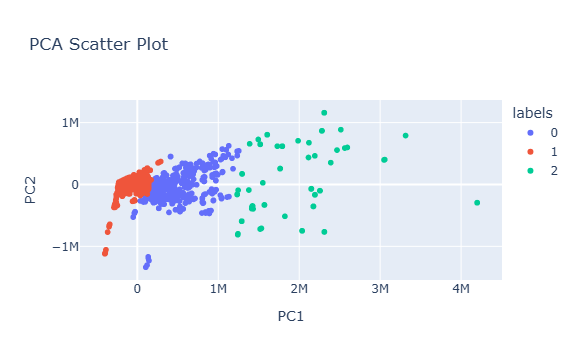

In [75]:
serve_scatter_plot(True, 3)

In [73]:
app.run(host="127.0.0.1", port=8050, debug=False)